In [ ]:
Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis Using Python in Jupyter Notebook
Student: Aditya Rayarapu
Course:  MSCS - 634 Advanced Big Data and Data Mining
Assignment: Lab 1
Dataset: Titanic Passenger Survival
Overview
Using 891 historical passenger records, this lab loads a CSV, creates meaningful visualizations, handles genuine missing data, detects and removes fare outliers, reduces features, standardizes numerical variables, and calculates descriptive statistics and correlations.

Research questions: How do survival outcomes differ by passenger class and sex? What patterns are visible in age and ticket fare? How do cleaning choices change the sample?

Source: Kaggle Titanic — Machine Learning from Disaster, also available as DataScienceDojo's public Titanic CSV. The file titanic.csv is bundled for reproducible, offline execution. The analysis is descriptive, not causal.

In [5]:
pip install numpy pandas matplotlib seaborn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 30.5 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 57.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 54.5 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 50.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 55.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [seaborn]9/10 [seaborn]ib]
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 18.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.7/28.7 MB 44.6 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /Users/adityarayarapu
Files: ['ScreenPal', '.config', 'Music', '.codegpt', '.copilot', 'screenshots', '.DS_Store', '.vscode-shared', '.CFUserTextEncoding', 'Untitled.ipynb', '.ServiceHub', '.templateengine', 'MSCS532_Assignment6', 'MSCS532_Assignment1', '.local', 'Projects', 'Pictures', 'jupyter_env', 'MSCS532_Assignment7', '.nuget', '.zsh_history', 'MSCS532_FinalProject', '.ipython', 'Desktop', 'Library', '.matplotlib', '.lesshst', '.IdentityService', '.android', '.cups', 'Sites', '.ms_openjdk_config', 'Public', 'SmartCricketTeamRotation', '.ssh', 'Movies', '.dotnet', 'Applications', '.Trash', 'python-3.14.6-macos11.pkg', 'MSCS532_Assignment2', '.ipynb_checkpoints', 'MSCS532_Assignment5', '.vmware', 'Documents', '.azuredatastudio', 'venv', '.anydesk', 'myenv', 'MSCS532_Assignment4', '.mono', '.vscode', 'MSCS532_Assignment3', '.aspnet', 'Downloads', '.python_history', '.gitconfig', '.viminfo', '.zsh_sessions']


In [9]:
%pip install --upgrade certifi

Note: you may need to restart the kernel to use updated packages.


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ssl
import certifi
from urllib.request import urlopen
from sklearn.preprocessing import StandardScaler
from IPython.display import display
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":160})
pd.set_option("display.max_columns",20)
IMG=Path("screenshots"); IMG.mkdir(exist_ok=True)
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
context = ssl.create_default_context(cafile=certifi.where())

with urlopen(url, context=context) as response:
    raw = pd.read_csv(response)
print("Loaded titanic.csv | rows, columns:", raw.shape)
display(raw.head())

Loaded titanic.csv | rows, columns: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [14]:
# CAPTURE: DATASET_HEAD
print("First five rows of the original dataset:")
display(raw.head())
print("Data types:")
display(raw.dtypes.rename("dtype").to_frame())

First five rows of the original dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Data types:


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


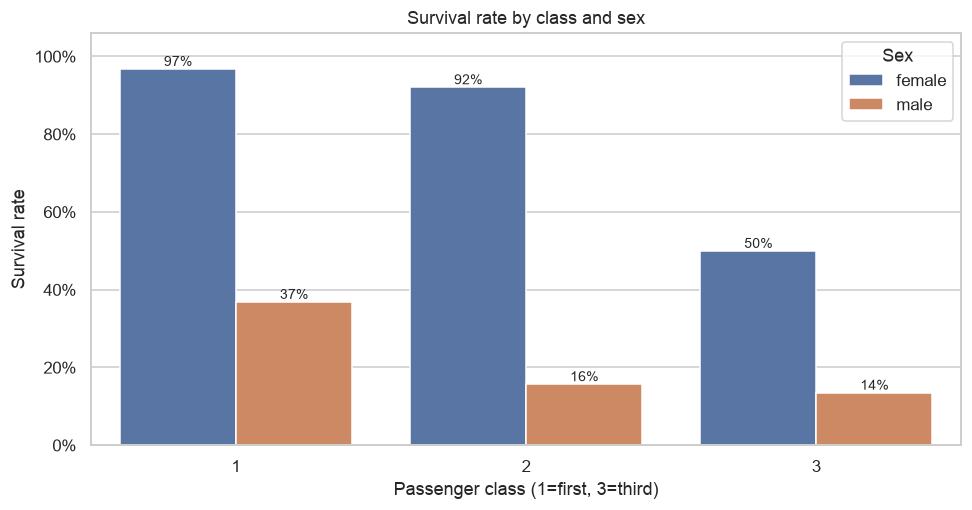

In [15]:
# CAPTURE: VISUAL_BAR
fig,ax=plt.subplots(figsize=(9,4.8))
sns.barplot(data=raw,x="Pclass",y="Survived",hue="Sex",errorbar=None,ax=ax)
ax.set(xlabel="Passenger class (1=first, 3=third)",ylabel="Survival rate",title="Survival rate by class and sex",ylim=(0,1.06))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_:f"{x:.0%}"))
for patch in ax.patches:
    if patch.get_height()>0:
        ax.annotate(f"{patch.get_height():.0%}",(patch.get_x()+patch.get_width()/2,patch.get_height()),ha="center",va="bottom",fontsize=9)
fig.tight_layout();fig.savefig(IMG/"02_survival_by_class_and_sex.png",bbox_inches="tight");plt.show()


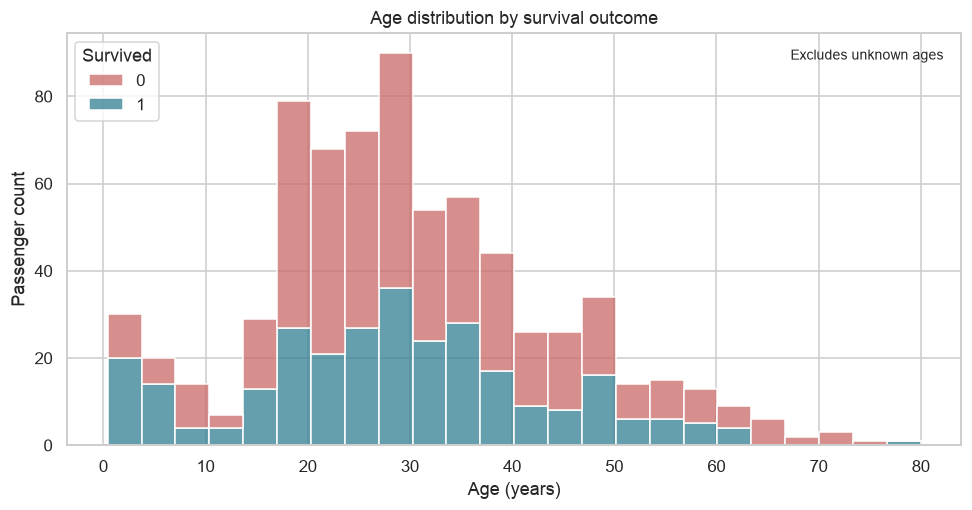

In [16]:
# CAPTURE: VISUAL_HISTOGRAM
fig,ax=plt.subplots(figsize=(9,4.8))
sns.histplot(data=raw,x="Age",hue="Survived",bins=24,multiple="stack",edgecolor="white",palette={0:"#C96A67",1:"#317E91"},ax=ax)
ax.set(xlabel="Age (years)",ylabel="Passenger count",title="Age distribution by survival outcome")
ax.text(.98,.96,"Excludes unknown ages",ha="right",va="top",transform=ax.transAxes,fontsize=9)
fig.tight_layout();fig.savefig(IMG/"03_age_histogram.png",bbox_inches="tight");plt.show()

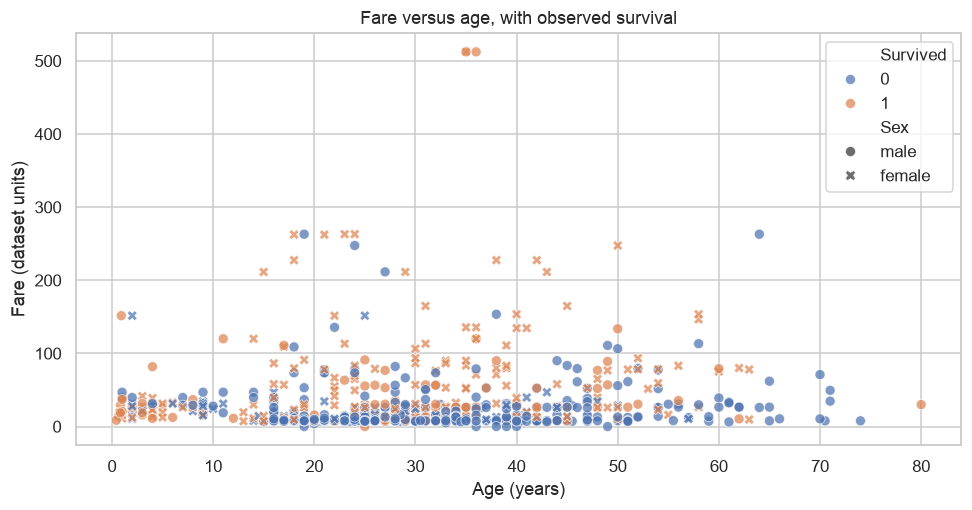

In [17]:
# CAPTURE: VISUAL_SCATTER
fig,ax=plt.subplots(figsize=(9,4.8))
sns.scatterplot(data=raw,x="Age",y="Fare",hue="Survived",style="Sex",alpha=.72,s=43,ax=ax)
ax.set(xlabel="Age (years)",ylabel="Fare (dataset units)",title="Fare versus age, with observed survival")
fig.tight_layout();fig.savefig(IMG/"04_fare_vs_age.png",bbox_inches="tight");plt.show()

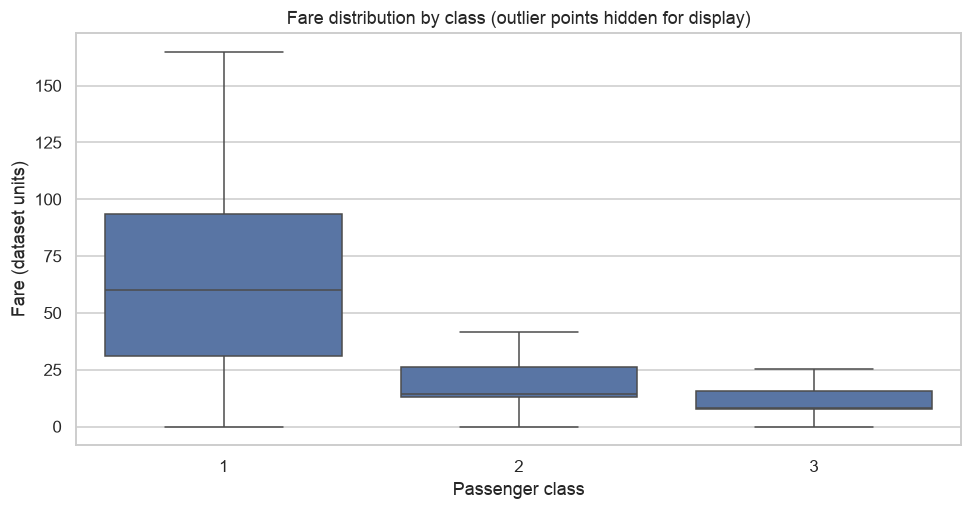

In [18]:
# CAPTURE: VISUAL_BOXPLOT
fig,ax=plt.subplots(figsize=(9,4.8))
sns.boxplot(data=raw,x="Pclass",y="Fare",showfliers=False,ax=ax)
ax.set(xlabel="Passenger class",ylabel="Fare (dataset units)",title="Fare distribution by class (outlier points hidden for display)")
fig.tight_layout();fig.savefig(IMG/"05_fare_boxplot.png",bbox_inches="tight");plt.show()

In [19]:
# CAPTURE: MISSING_BEFORE
print("Missing counts before handling:")
display(raw.isna().sum().rename("Missing before").to_frame())
print("Examples of passengers with missing ages or embarkation:")
display(raw.loc[raw[["Age","Embarked"]].isna().any(axis=1),["PassengerId","Pclass","Age","Embarked"]].head(8))

Missing counts before handling:


,Missing before
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Examples of passengers with missing ages or embarkation:


,PassengerId,Pclass,Age,Embarked
5,6,3,NaN,Q
17,18,2,NaN,S
19,20,3,NaN,C
26,27,3,NaN,C
28,29,3,NaN,Q
29,30,3,NaN,S
31,32,1,NaN,C
32,33,3,NaN,Q


In [20]:
clean=raw.drop(columns="Cabin").copy()
class_age=clean.groupby("Pclass")["Age"].transform("median")
clean["Age"]=clean["Age"].fillna(class_age).fillna(clean["Age"].median())
clean["Embarked"]=clean["Embarked"].fillna(clean["Embarked"].mode().iat[0])

In [21]:
# CAPTURE: MISSING_AFTER
print("Missing counts after handling:")
display(clean.isna().sum().rename("Missing after").to_frame())
print("Before:",raw.shape,"After:",clean.shape)
assert clean.isna().sum().sum()==0

Missing counts after handling:


,Missing after
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


Before: (891, 12) After: (891, 11)


In [22]:
# CAPTURE: IQR_DETECTION
q1,q3=clean.Fare.quantile([.25,.75]);iqr=q3-q1
lower=q1-3*iqr;upper=q3+3*iqr
flag=(clean.Fare<lower)|(clean.Fare>upper)
print(f"Q1={q1:.4f}, Q3={q3:.4f}, IQR={iqr:.4f}")
print(f"Conservative lower fence={lower:.4f}, upper fence={upper:.4f}")
print(f"Flagged outliers: {flag.sum()} / {len(clean)} ({flag.mean():.1%})")
display(clean.loc[flag,["PassengerId","Pclass","Fare","Survived"]].sort_values("Fare",ascending=False).head(10))

Q1=7.9104, Q3=31.0000, IQR=23.0896
Conservative lower fence=-61.3584, upper fence=100.2688
Flagged outliers: 53 / 891 (5.9%)


,PassengerId,Pclass,Fare,Survived
258,259,1,512.3292,1
737,738,1,512.3292,1
679,680,1,512.3292,1
27,28,1,263.0000,0
341,342,1,263.0000,1
88,89,1,263.0000,1
438,439,1,263.0000,0
311,312,1,262.3750,1
742,743,1,262.3750,1
299,300,1,247.5208,1


Data before outlier removal: (891, 11)
Data after outlier removal: (838, 11)
Max fare before: 512.3292 | max fare after: 93.5


,PassengerId,Pclass,Age,Fare,Survived
0,1,3,22.0,7.2500,0
1,2,1,38.0,71.2833,1
2,3,3,26.0,7.9250,1
3,4,1,35.0,53.1000,1
4,5,3,35.0,8.0500,0


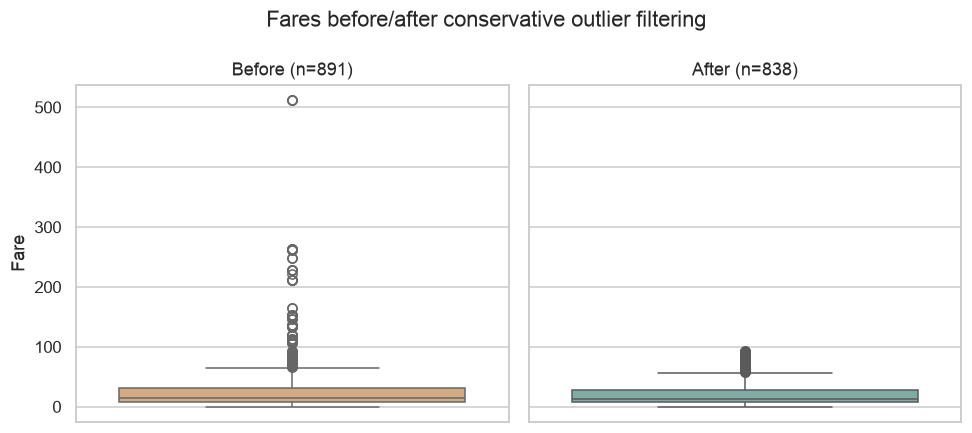

In [23]:
# CAPTURE: IQR_AFTER
no_outliers=clean.loc[~flag].copy().reset_index(drop=True)
print("Data before outlier removal:",clean.shape)
print("Data after outlier removal:",no_outliers.shape)
print("Max fare before:",clean.Fare.max(),"| max fare after:",no_outliers.Fare.max())
display(no_outliers[["PassengerId","Pclass","Age","Fare","Survived"]].head())
fig,axs=plt.subplots(1,2,figsize=(9,4),sharey=True)
sns.boxplot(y=clean.Fare,ax=axs[0],color="#DFAB78")
sns.boxplot(y=no_outliers.Fare,ax=axs[1],color="#78B3A9")
axs[0].set(title=f"Before (n={len(clean)})",ylabel="Fare")
axs[1].set(title=f"After (n={len(no_outliers)})",ylabel="Fare")
fig.suptitle("Fares before/after conservative outlier filtering")
fig.tight_layout();fig.savefig(IMG/"10_outliers_before_after.png",bbox_inches="tight");plt.show()

In [24]:
# CAPTURE: REDUCTION_BEFORE_AFTER
print("BEFORE reduction:",no_outliers.shape,"|",list(no_outliers.columns))
display(no_outliers.head(3))
reduced=no_outliers.drop(columns=["PassengerId","Name","Ticket"]).copy()
print("AFTER reduction:",reduced.shape,"|",list(reduced.columns))
display(reduced.head(3))

BEFORE reduction: (838, 11) | ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S


AFTER reduction: (838, 8) | ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S


In [25]:
# CAPTURE: SCALING_BEFORE_AFTER
numeric_features=["Age","Fare","SibSp","Parch"]
scaled=reduced.copy();scaler=StandardScaler()
scaled[numeric_features]=scaler.fit_transform(reduced[numeric_features])
print("BEFORE z-score scaling:")
display(reduced[numeric_features].head(6).round(3))
print("AFTER z-score scaling:")
display(scaled[numeric_features].head(6).round(3))
print("Mean and population standard deviation after scaling:")
display(pd.DataFrame({"Mean":scaled[numeric_features].mean(),"Population SD":scaled[numeric_features].std(ddof=0)}).round(7))

BEFORE z-score scaling:


,Age,Fare,SibSp,Parch
0,22.0,7.250,1,0
1,38.0,71.283,1,0
2,26.0,7.925,0,0
3,35.0,53.100,1,0
4,35.0,8.050,0,0
5,24.0,8.458,0,0


AFTER z-score scaling:


,Age,Fare,SibSp,Parch
0,-0.520,-0.728,0.435,-0.446
1,0.694,2.348,0.435,-0.446
2,-0.217,-0.696,-0.460,-0.446
3,0.467,1.474,0.435,-0.446
4,0.467,-0.690,-0.460,-0.446
5,-0.368,-0.670,-0.460,-0.446


Mean and population standard deviation after scaling:


,Mean,Population SD
Age,-0.0,1.0
Fare,0.0,1.0
SibSp,0.0,1.0
Parch,0.0,1.0


In [26]:
# CAPTURE: INFO_DESCRIBE
print("Final analysis DataFrame.info():")
reduced.info()
print("Final analysis DataFrame.describe(include='all').T:")
display(reduced.describe(include="all").T.round(3))

Final analysis DataFrame.info():
<class 'pandas.DataFrame'>
RangeIndex: 838 entries, 0 to 837
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  838 non-null    int64  
 1   Pclass    838 non-null    int64  
 2   Sex       838 non-null    str    
 3   Age       838 non-null    float64
 4   SibSp     838 non-null    int64  
 5   Parch     838 non-null    int64  
 6   Fare      838 non-null    float64
 7   Embarked  838 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 52.5 KB
Final analysis DataFrame.describe(include='all').T:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Survived,838.0,NaN,NaN,NaN,0.361575,0.480744,0.0,0.0,0.0,1.0,1.0
Pclass,838.0,NaN,NaN,NaN,2.391408,0.792451,1.0,2.0,3.0,3.0,3.0
Sex,838,2,male,558,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,838.0,NaN,NaN,NaN,28.85352,13.180901,0.42,22.0,26.0,36.0,80.0
SibSp,838.0,NaN,NaN,NaN,0.51432,1.117541,0.0,0.0,0.0,1.0,8.0
Parch,838.0,NaN,NaN,NaN,0.349642,0.784067,0.0,0.0,0.0,0.0,6.0
Fare,838.0,NaN,NaN,NaN,22.411942,20.827218,0.0,7.8958,13.0,27.7208,93.5
Embarked,838,3,S,622,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
# CAPTURE: CENTRAL_TENDENCY
values=reduced[["Age","Fare","SibSp","Parch"]]
central=pd.DataFrame({"Minimum":values.min(),"Maximum":values.max(),"Mean":values.mean(),
                      "Median":values.median(),"Mode (first if tied)":values.mode().iloc[0]})
print("Minimum, maximum, mean, median, and mode:")
display(central.round(3))

Minimum, maximum, mean, median, and mode:


,Minimum,Maximum,Mean,Median,Mode (first if tied)
Age,0.42,80.0,28.854,26.0,24.00
Fare,0.00,93.5,22.412,13.0,8.05
SibSp,0.00,8.0,0.514,0.0,0.00
Parch,0.00,6.0,0.350,0.0,0.00


In [28]:
# CAPTURE: DISPERSION
q_25=values.quantile(.25);q_75=values.quantile(.75)
dispersion=pd.DataFrame({"Range":values.max()-values.min(),"Q1":q_25,"Q2 (Median)":values.median(),
                         "Q3":q_75,"IQR":q_75-q_25,"Sample variance":values.var(ddof=1),
                         "Sample std. dev.":values.std(ddof=1)})
print("Range, quartiles, interquartile range, sample variance and standard deviation:")
display(dispersion.round(3))

Range, quartiles, interquartile range, sample variance and standard deviation:


,Range,Q1,Q2 (Median),Q3,IQR,Sample variance,Sample std. dev.
Age,79.58,22.000,26.0,36.000,14.000,173.736,13.181
Fare,93.50,7.896,13.0,27.721,19.825,433.773,20.827
SibSp,8.00,0.000,0.0,1.000,1.000,1.249,1.118
Parch,6.00,0.000,0.0,0.000,0.000,0.615,0.784


Pearson correlation matrix (DataFrame.corr):


,Survived,Pclass,Age,SibSp,Parch,Fare
Survived,1.000,-0.303,-0.061,-0.044,0.073,0.276
Pclass,-0.303,1.000,-0.432,0.106,0.093,-0.644
Age,-0.061,-0.432,1.000,-0.245,-0.187,0.183
SibSp,-0.044,0.106,-0.245,1.000,0.419,0.343
Parch,0.073,0.093,-0.187,0.419,1.000,0.226
Fare,0.276,-0.644,0.183,0.343,0.226,1.000


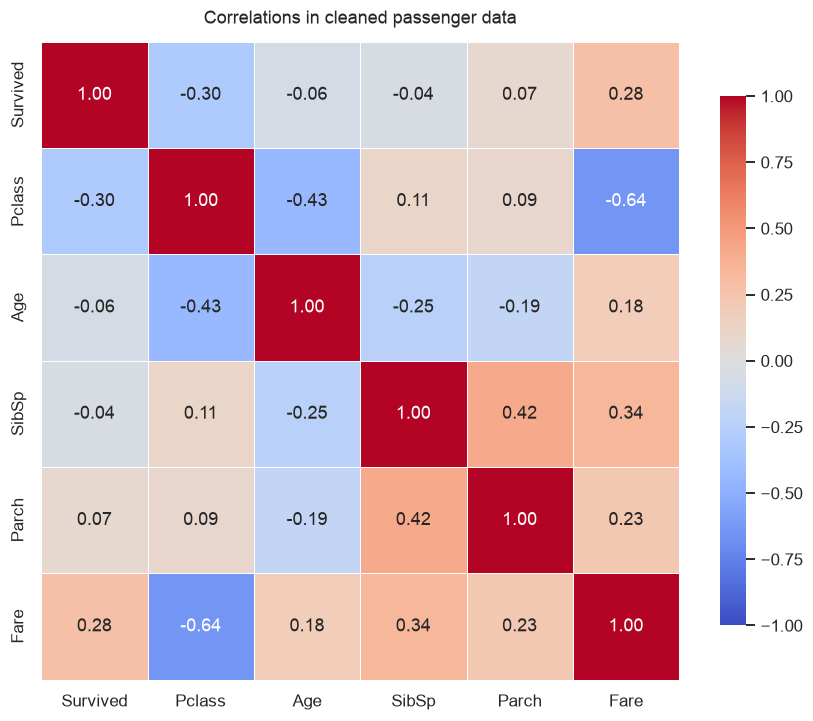

In [29]:
# CAPTURE: CORRELATIONS
corr=reduced[["Survived","Pclass","Age","SibSp","Parch","Fare"]].corr()
print("Pearson correlation matrix (DataFrame.corr):")
display(corr.round(3))
fig,ax=plt.subplots(figsize=(8,6.6))
sns.heatmap(corr,annot=True,fmt=".2f",cmap="coolwarm",center=0,vmin=-1,vmax=1,
            square=True,linewidths=.5,cbar_kws={"shrink":.83},ax=ax)
ax.set_title("Correlations in cleaned passenger data",pad=12)
fig.tight_layout();fig.savefig(IMG/"16_correlation_heatmap.png",bbox_inches="tight");plt.show()

In [30]:
# CAPTURE: FINAL_INSIGHTS
print(f"Original rows: {len(raw)}; after outlier removal: {len(reduced)}")
print(f"Missing ages: {raw.Age.isna().sum()} ({raw.Age.isna().mean():.1%})")
print(f"Missing cabins: {raw.Cabin.isna().sum()} ({raw.Cabin.isna().mean():.1%})")
print(f"High-fare outlier rows: {flag.sum()} ({flag.mean():.1%})")
print(f"Survival rate originally: {raw.Survived.mean():.1%}")
print(f"Survival rate after filtering: {reduced.Survived.mean():.1%}")
print("Original survival by passenger class:")
display(raw.groupby("Pclass")["Survived"].agg(["count","mean"]).rename(columns={"mean":"survival fraction"}).round(3))
print("Original survival by sex:")
display(raw.groupby("Sex")["Survived"].agg(["count","mean"]).rename(columns={"mean":"survival fraction"}).round(3))

Original rows: 891; after outlier removal: 838
Missing ages: 177 (19.9%)
Missing cabins: 687 (77.1%)
High-fare outlier rows: 53 (5.9%)
Survival rate originally: 38.4%
Survival rate after filtering: 36.2%
Original survival by passenger class:


,count,survival fraction
Pclass,,
1,216,0.630
2,184,0.473
3,491,0.242


Original survival by sex:


,count,survival fraction
Sex,,
female,314,0.742
male,577,0.189


In [31]:
# Export final cleaned data and verify expected workflow stages
assert raw.shape==(891,12)
assert clean.isna().sum().sum()==0
assert len(reduced)==838
assert reduced.shape[1]==8
assert (scaled[numeric_features].mean().abs()<1e-10).all()
reduced.to_csv("titanic_cleaned_for_analysis.csv",index=False)
print("Validation passed. Cleaned CSV exported; chart PNGs saved to screenshots/.")

Validation passed. Cleaned CSV exported; chart PNGs saved to screenshots/.
